# Inhibition in a circuit
## Motivation
The equilibtium between excitation and inhibition is a fundamental principle in cortical dynamics. The relative proportion of inhibitory interneurons ($p_I$) regulates the activity in recurrent SNN, avoiding hyperexcitability and complete neuronal supression. Here we will explore how the proportion of inhibitory neurons affects the energetic efficiency of the excitatory computations in a neural network.

**Hypothesis:** a low proportion of interneurons leads to excessive excitatory firing with poor efficiency, a high proportion suppresses excitatory activity and diminishes efficiency, and an intermediate proportion provides the optimal balance for efficient computation (specifically the one seen in cortical circuits $p_I \sim 0.2$).

## Methods
To study this we consider a network of $N=1000$ neurons with a variable inhibitory proportion, i.e. $p_I \in \left[ 0, 0.5 \right]$. We use the Izhikevich (dimensionless) model to define a RS-dynamics for excitatory neurons and a FS-dynamics for inhibitory neurons, distinguishing then between two network populations: $N_E$ and $N_I$.

The network is initialized with reccurent connections (avoiding auto-recurrence) and sparse connectivity $p_{\text{conn}}=0.1$. We consider a gaussian initialization $\mathcal{N}(0.6, 02)$ for excitatory neurons and $\mathcal{N}(1.0, 02)$, and clamp their values according to phisiological values ($w_E^\text{max}=2.5$ and $w_I^\text{max}=4.0$). Additionaly, synaptic currents are calculated through an exponential decay of the presynaptic traces, i.e.
$$
s_j(t+\Delta t)=e^{-\Delta t / \tau_j}s_j(t) + 1_{\{\text{spike}_j (t)\}},
$$
where $\tau_E = 8 \text{ms}$ and $\tau_I = 5 \text{ms}$.

We further apply a symetric STDP plasticity over the weights: LTP ($\tau_+ = 20 \text{ms}$, $A_+=0.01$) and LTD ($\tau_- = 20 \text{ms}$, $A_-=0.012$). The update is scaled through a learning rate $\eta=0.1$.

### Metrics
We define **efficiency** as a measure of how effectively the network converts energy expenditure into useful spiking output. Since we aim to quantify how efficient the network is at transmitting information, a first approximation is to assume that an efficient network is one that produces a significant number of excitatory spikes per unit of energy invested. Accordingly, we define efficiency as the ratio
$$
\text{Ef} = \frac{S_E}{\mathcal{E}_E},
$$
where $S_E$ is the total number of excitatory spikes and $\mathcal{E}_E$ is the cumulative energetic cost. Intuitively, efficiency will be low if the network produces many spikes at a disproportionate energetic cost, or if it consumes little energy but generates very few spikes. Maximum efficiency is achieved when the network produces a meaningful level of excitatory output while minimizing energetic expenditure.

In this model, the energy cost is not computed from the actual biophysical mechanisms of ATP consumption, such as ionic pumps or channel kinetics. Instead, we employ an **energy proxy** that captures the integrated synaptic effort required to sustain excitatory activity. At each time step, we calculate the absolute value of the synaptic current received by each excitatory neuron,
$$
\mathcal{E}_E = \sum_t \sum_{i\in E} |I_i(t)|\Delta t,
$$
where $I_i(t)$ is the total synaptic current into excitatory neuron $i$. Taking the absolute value ensures that both excitatory and inhibitory currents contribute positively to the energetic cost, reflecting the fact that both types of ionic flux demand resources even though they have opposite functional effects on membrane potential.

## Results and discussion
The sweep over the proportion of inhibitory neurons revealed three regimes: with low inhibition the network exhibits excessive excitatory firing at high energetic cost, resulting in poor efficiency; with high inhibition excitatory activity is largely suppressed, leading to reduced efficiency due to minimal output; and at an intermediate level inhibition stabilizes excitatory activity without silencing it, yielding the highest efficiency. Notably, the proportion of inhibitory neurons that maximizes efficiency in our simulations is $p_I=0.22$, a value set by the chosen hyperparameters but closely aligned with the canonical cortical fraction of around 20%. This alignment suggests that cortical networks may operate near an energetic optimum, balancing excitatory and inhibitory activity to maximize information transmission per unit energy. Such correspondence highlights a potential evolutionary pressure toward efficient computation and provides a guiding principle for designing energy-efficient spiking neural networks.


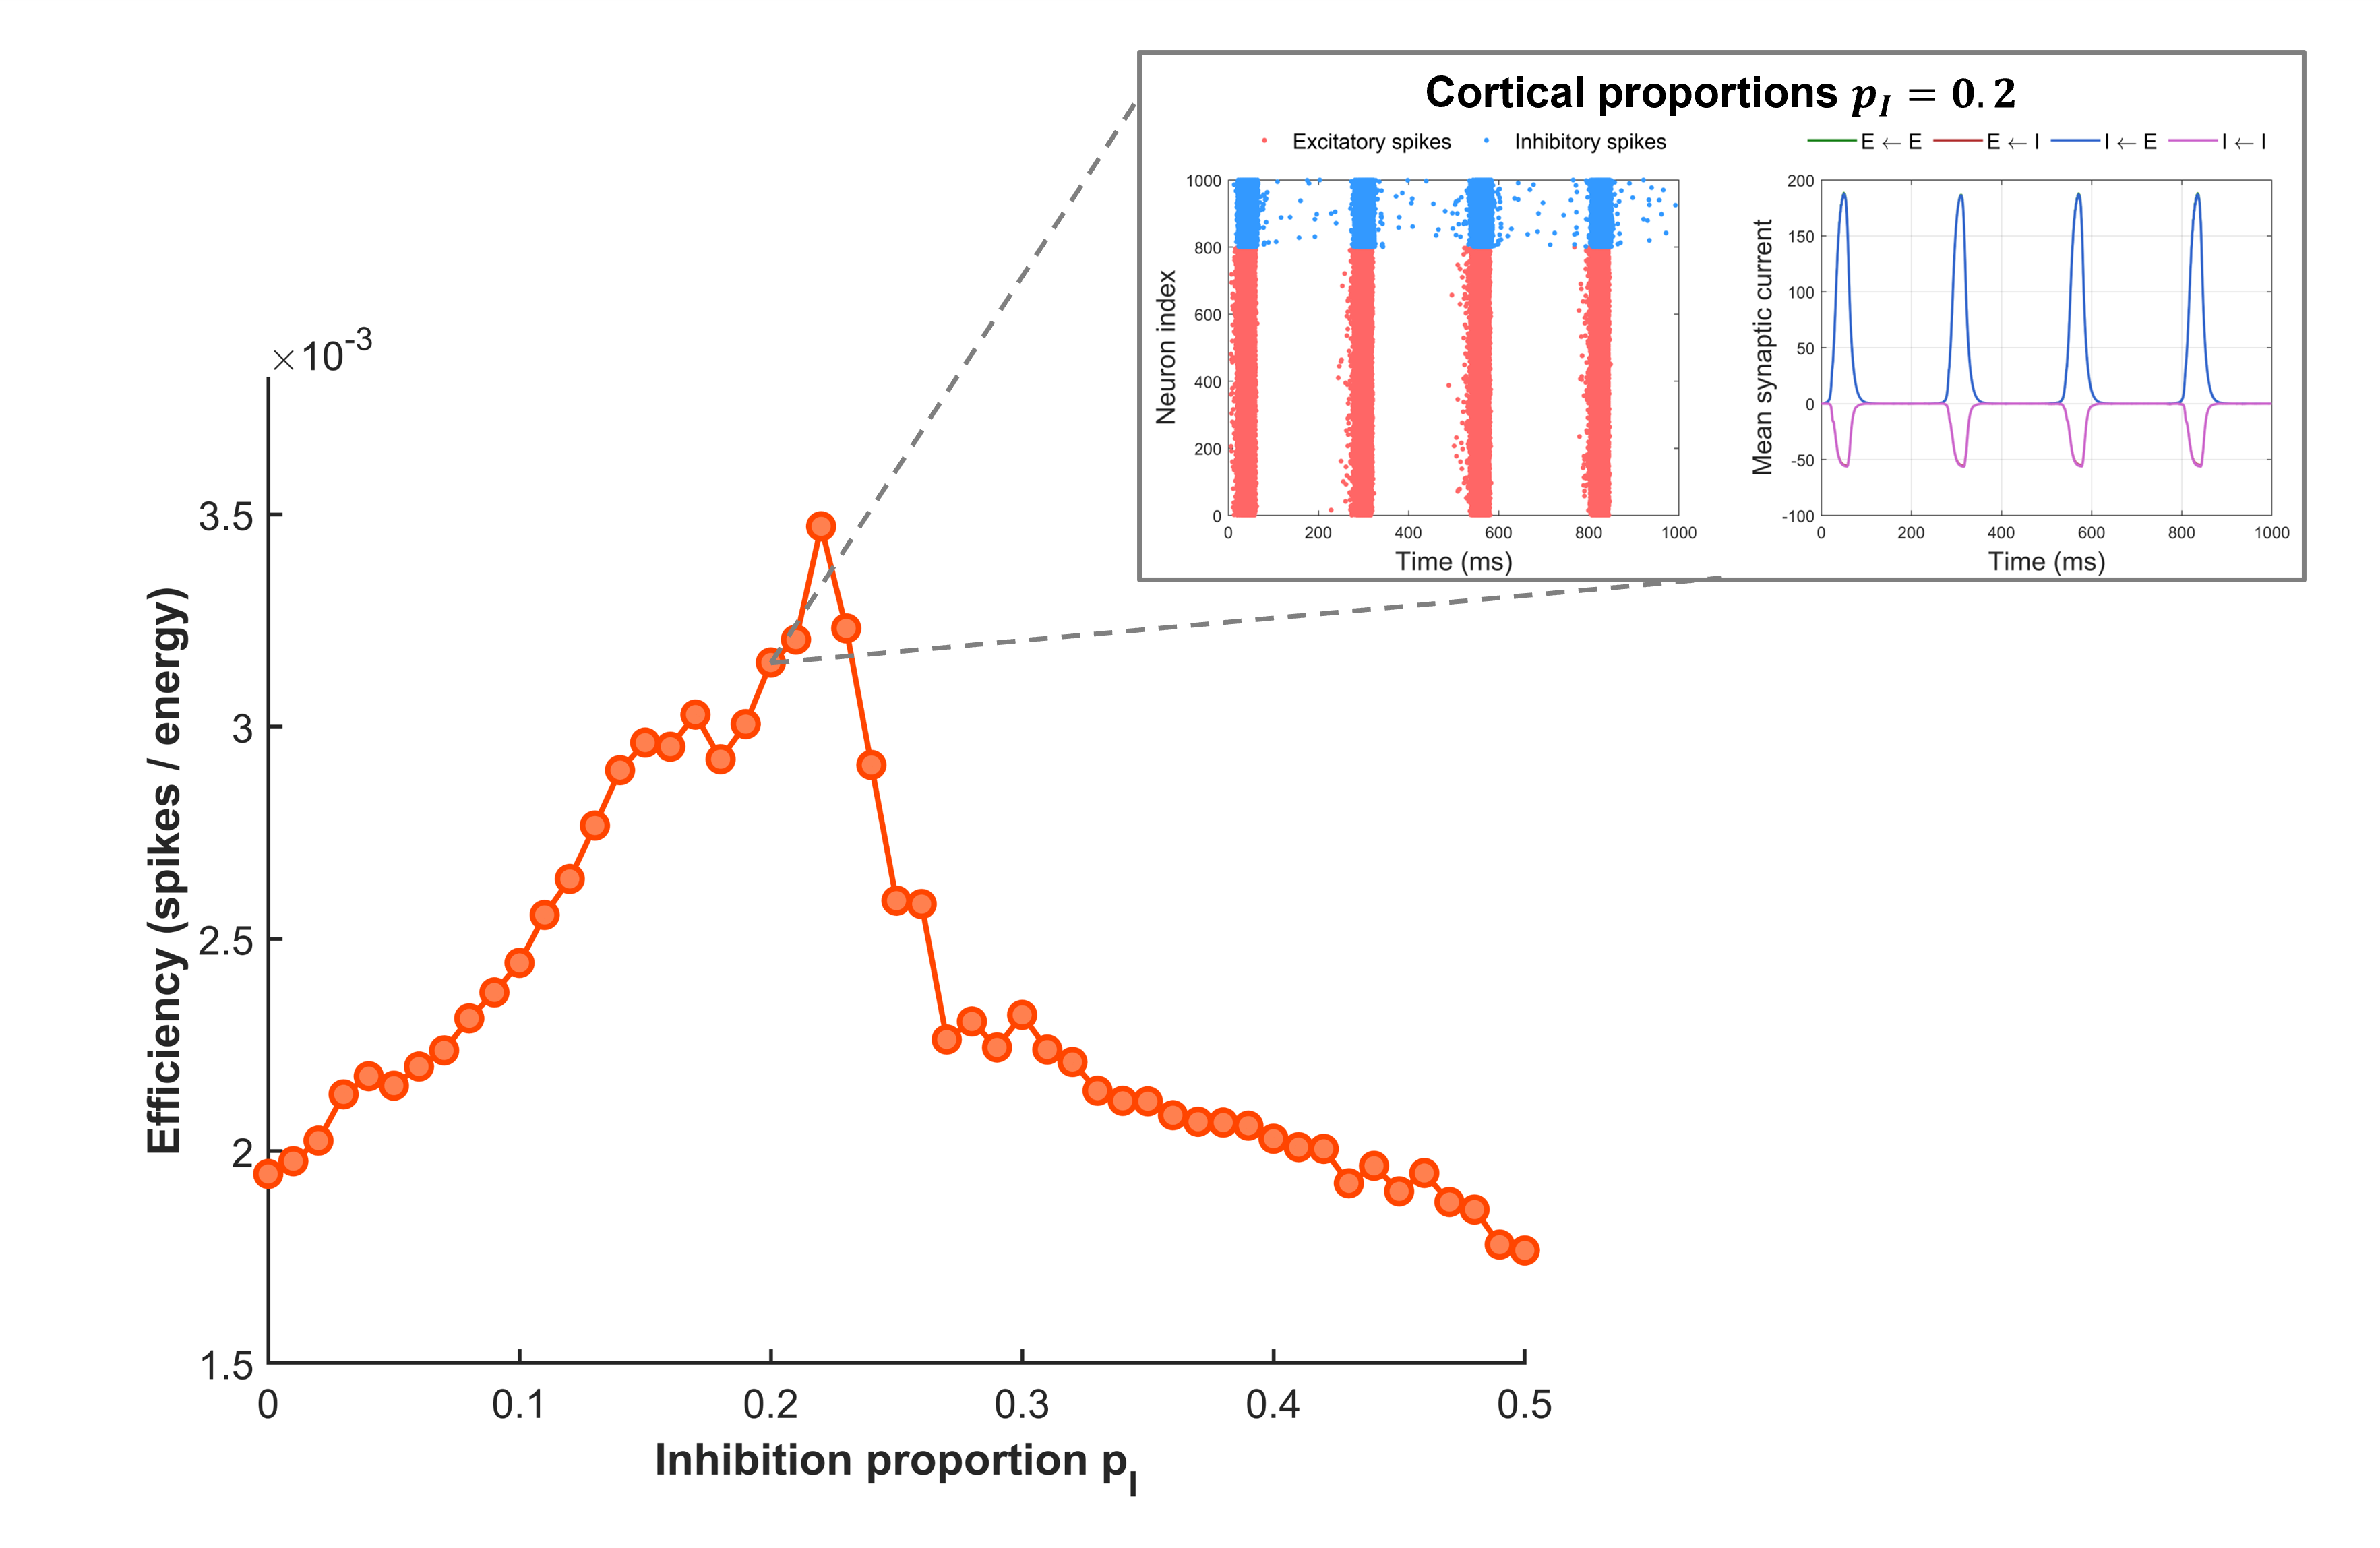

In [3]:
from IPython.display import Image, display
display(Image('inhibitoryEff_picture.png'))